In [ ]:
import os
import re
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
# 1. Get the directory of the current script
SCRIPT_DIR = Path.cwd()

# 2. Point to your data folder relative to this script
DATA_DIR = SCRIPT_DIR / "../data/images/images"

def get_image_dataset(foldername, DATA_DIR=DATA_DIR):
    flip = DATA_DIR/foldername/"flip"
    notFlip = DATA_DIR/foldername/"notflip"

    flipping_images = list(flip.glob("*"))
    not_flipping_images = list(notFlip.glob("*"))

    return flipping_images, not_flipping_images, flip, notFlip


In [3]:
flip_images, notFlip_images, _, _ = get_image_dataset(foldername="testing")

print("Flipping images:", len(flip_images))
print("Not flipping images:", len(notFlip_images))
print("Total images:", len(flip_images) + len(notFlip_images))

Flipping images: 290
Not flipping images: 307
Total images: 597


In [21]:
all_images = flip_images + notFlip_images

extensions = Counter(
    image.suffix.lower()
    for image in all_images
)

print(extensions)

Counter({'.jpg': 597})


In [63]:
def extract_image_metadata(image_path, label):
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    height, width, channels = image.shape

    # Extract video ID and frame number
    filename = image_path.stem

    match = re.match(r"(.+?)_(\d+)$", filename)

    if match:
        video_id = match.group(1)
        frame_number = int(match.group(2))
    else:
        video_id = None
        frame_number = None

    return {
        "image_path": str(image_path),
        "filename": image_path.name,
        "video_id": video_id,
        "frame_number": frame_number,
        "label": label,
        "width": width,
        "height": height,
        "channels": channels,
        "file_size_kb": image_path.stat().st_size / 1024
    }

In [64]:
metadata = []

for image_path in flip_images:
    result = extract_image_metadata(image_path, label=1)

    if result is not None:
        result = {"id": len(metadata), **result}
        metadata.append(result)

for image_path in notFlip_images:
    result = extract_image_metadata(image_path, label=0)

    if result is not None:
        result = {"id": len(metadata), **result}
        metadata.append(result)

df = pd.DataFrame(metadata)

print(df.head())

   id                                         image_path            filename  \
0   0  c:\Users\Shane\Desktop\Other\vscode\Github Pro...  0001_000000010.jpg   
1   1  c:\Users\Shane\Desktop\Other\vscode\Github Pro...  0001_000000011.jpg   
2   2  c:\Users\Shane\Desktop\Other\vscode\Github Pro...  0001_000000012.jpg   
3   3  c:\Users\Shane\Desktop\Other\vscode\Github Pro...  0001_000000013.jpg   
4   4  c:\Users\Shane\Desktop\Other\vscode\Github Pro...  0001_000000014.jpg   

  video_id  frame_number  label  width  height  channels  file_size_kb  
0     0001            10      1   1080    1920         3    322.095703  
1     0001            11      1   1080    1920         3    322.178711  
2     0001            12      1   1080    1920         3    325.963867  
3     0001            13      1   1080    1920         3    331.750977  
4     0001            14      1   1080    1920         3    328.498047  


In [28]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
print(df.info())

print("\nSummary statistics:")
print(df.describe())

Dataset shape: (2392, 8)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   filename      2392 non-null   str    
 1   video_id      2392 non-null   str    
 2   frame_number  2392 non-null   int64  
 3   label         2392 non-null   int64  
 4   width         2392 non-null   int64  
 5   height        2392 non-null   int64  
 6   channels      2392 non-null   int64  
 7   file_size_kb  2392 non-null   float64
dtypes: float64(1), int64(5), str(2)
memory usage: 149.6 KB
None

Summary statistics:
       frame_number        label   width  height  channels  file_size_kb
count   2392.000000  2392.000000  2392.0  2392.0    2392.0   2392.000000
mean      16.607441     0.485786  1080.0  1920.0       3.0    310.794751
std        8.710656     0.499902     0.0     0.0       0.0     58.478180
min        1.000000     0.000000  1080.0  1920.0   

In [35]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate filenames:")
print(df.duplicated(subset=["filename", "label"]).sum())

print("\nMissing video IDs:")
print(df["video_id"].isnull().sum())

print("\nMissing frame numbers:")
print(df["frame_number"].isnull().sum())

Missing values:
filename        0
video_id        0
frame_number    0
label           0
width           0
height          0
channels        0
file_size_kb    0
dtype: int64

Duplicate filenames:
0

Missing video IDs:
0

Missing frame numbers:
0


In [40]:
class_counts = df["label"].value_counts().sort_index()

print(f"{class_counts}\n\n")

class_percentages = (
    df["label"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(class_percentages)

label
0    1230
1    1162
Name: count, dtype: int64


label
0    51.421405
1    48.578595
Name: proportion, dtype: float64


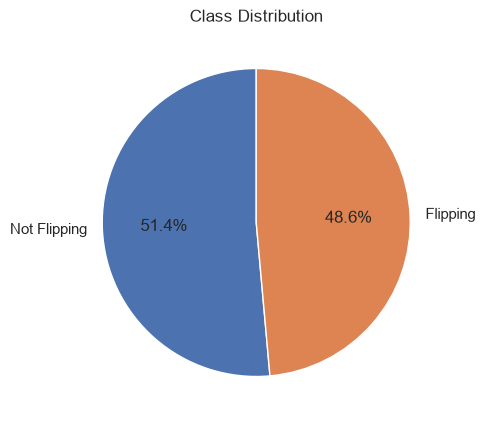

In [42]:
plt.figure(figsize=(7, 5))

plt.pie(
    class_counts,
    labels=["Not Flipping", "Flipping"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Class Distribution")

plt.show()

In [47]:
print("Unique videos:", df["video_id"].nunique())

print("\nVideos per class:")
print(
    df.groupby("label")["video_id"]
    .nunique()
)

video_counts = (
    df.groupby(["video_id", "label"])
    .size()
    .reset_index(name="image_count")
)

print(f"\n\n{video_counts.head(10)}")

Unique videos: 65

Videos per class:
label
0    52
1    65
Name: video_id, dtype: int64


  video_id  label  image_count
0     0001      0           25
1     0001      1           15
2     0002      0           22
3     0002      1            9
4     0003      0           26
5     0003      1           22
6     0004      0           26
7     0004      1           20
8     0005      0           25
9     0005      1           25


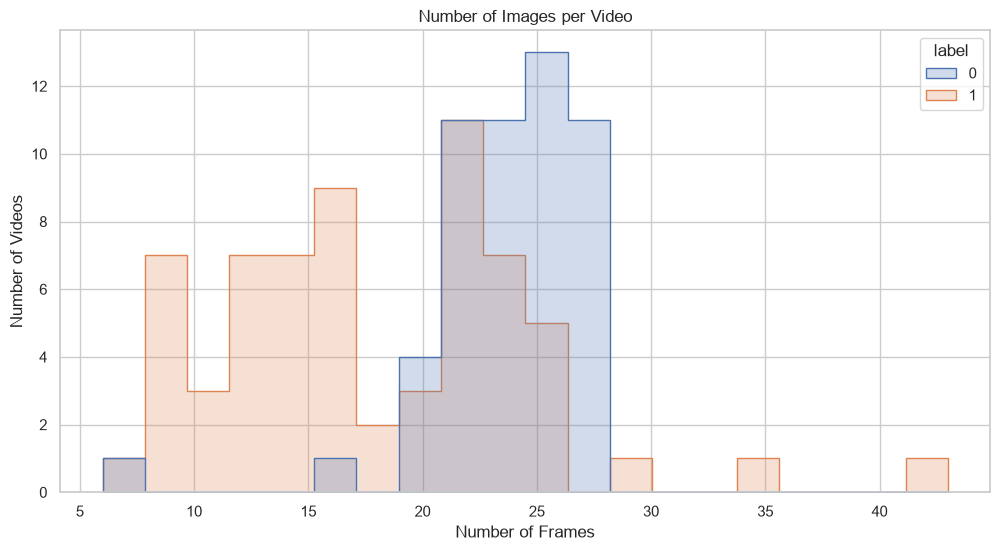

In [48]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=video_counts,
    x="image_count",
    hue="label",
    bins=20,
    element="step"
)

plt.title("Number of Images per Video")
plt.xlabel("Number of Frames")
plt.ylabel("Number of Videos")

plt.show()

In [58]:
def display_random_images(df, flip_dir, notFlip_dir, label, n=9):
    class_df = df[df["label"] == label]

    samples = class_df.sample(
        n=min(n, len(class_df)),
        random_state=RANDOM_STATE
    )

    fig, axes = plt.subplots(3, 3, figsize=(12, 10))

    for ax, (_, row) in zip(axes.flatten(), samples.iterrows()):
        image_dir = flip_dir if label == 1 else notFlip_dir
        image_path = image_dir / row["filename"]

        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        ax.imshow(image)
        ax.set_title(f"ID: {row['id']} | {row['filename']}")
        ax.axis("off")

    # Hide unused subplot axes if fewer than 9 images are sampled
    for ax in axes.flatten()[len(samples):]:
        ax.axis("off")

    plt.suptitle(
        "Flipping" if label == 1 else "Not Flipping",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

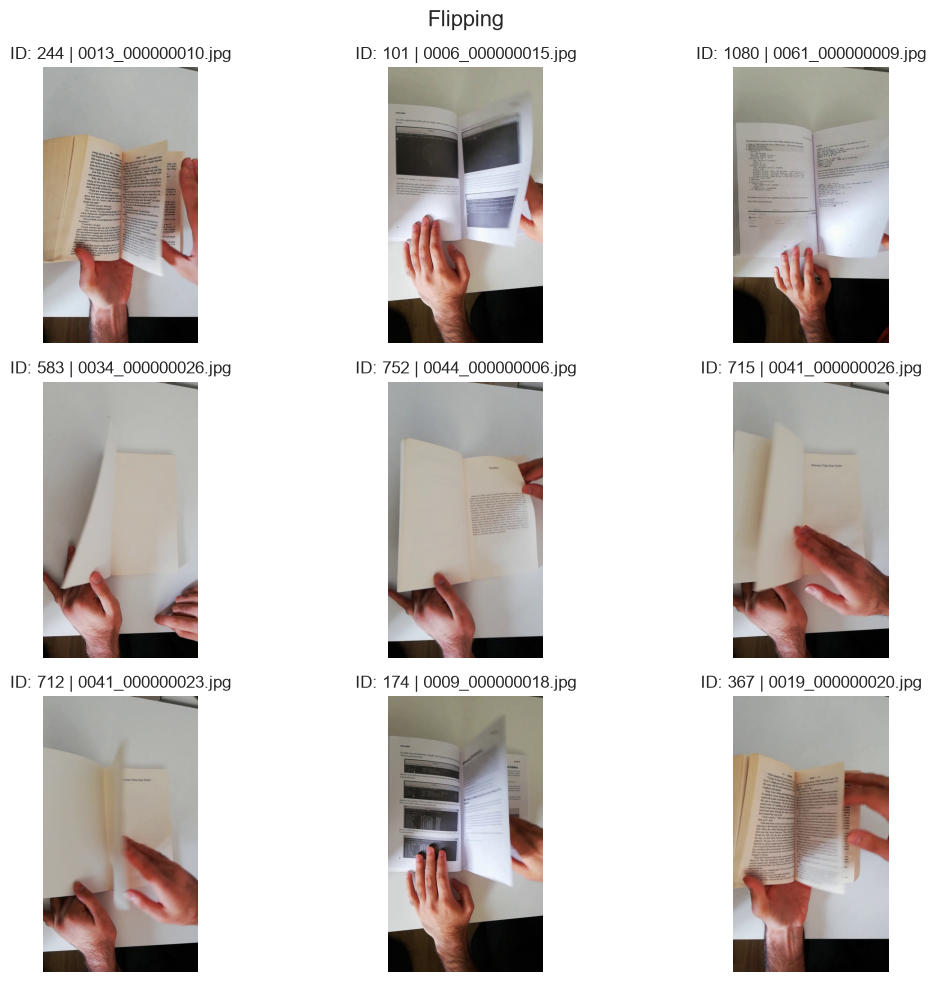

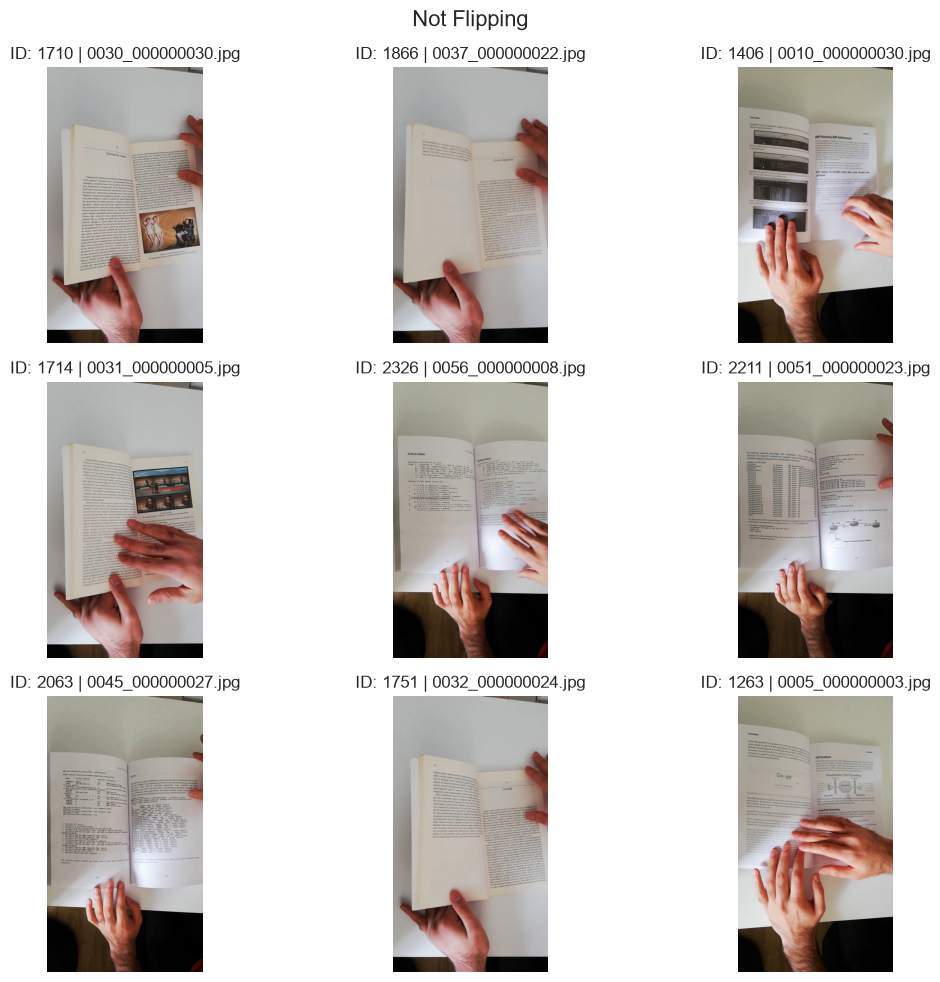

In [60]:
_, _, flip_dir, notFlip_dir = get_image_dataset("training")

display_random_images(df, flip_dir=flip_dir, notFlip_dir=notFlip_dir, label=1)
display_random_images(df, flip_dir=flip_dir, notFlip_dir=notFlip_dir, label=0)

In [65]:
def calculate_image_statistics(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray)
    contrast = np.std(gray)

    return {
        "brightness": brightness,
        "contrast": contrast
    }

image_stats = []

for _, row in df.iterrows():
    stats = calculate_image_statistics(row["image_path"])

    if stats is not None:
        image_stats.append(stats)

stats_df = pd.DataFrame(image_stats)

df = pd.concat(
    [df.reset_index(drop=True), stats_df],
    axis=1
)

In [67]:
print(
    df.groupby("label")[["brightness", "contrast"]]
    .agg(["mean", "median", "std", "min", "max"])
)

       brightness                                                  contrast  \
             mean      median        std         min         max       mean   
label                                                                         
0      141.834217  140.256699   9.462292  122.605440  160.129963  58.414978   
1      137.069325  140.138556  12.177330  110.592544  161.554353  56.686233   

                                                  
          median       std        min        max  
label                                             
0      62.213038  7.800612  42.341435  70.402091  
1      56.191983  7.084144  42.857888  72.907392  


In [ ]:
#check if adjacent and non adjacent frames have correlations between them

#consider augmenting data during preprocessing (brightness adjustment, transforming images, ...) based on the model I choose
#normalize pixels

#look into cnn models: e.g. resnet